In [1]:
import pandas as pd
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

project_dir = Path.home() / "Downloads" / "Hate-Speech-Detection"
data_dir = project_dir / "data" / "processed"

train_df = pd.read_csv(data_dir / "hatexplain_train.csv")
val_df = pd.read_csv(data_dir / "hatexplain_validation.csv")

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

model.fit(train_df["text"], train_df["label"])

print("Baseline model loaded and trained!")

Baseline model loaded and trained!


In [2]:
import shap

class_names = {
    0: "Hate speech",
    1: "Normal",
    2: "Offensive"
}

sample_text = val_df.iloc[0]["text"]
prediction = model.predict([sample_text])[0]

print("Post:", sample_text)
print("Actual label:", class_names[val_df.iloc[0]["label"]])
print("Predicted label:", class_names[prediction])

Post: me getting books from the library about queer cowboys and homoeroticism in cinema instead of anything useful for my thesis
Actual label: Normal
Predicted label: Normal


In [6]:
import shap

vectorizer = model.named_steps["tfidf"]
classifier = model.named_steps["classifier"]

# Use a small background sample from training data
background_text = train_df["text"].sample(100, random_state=42)
background = vectorizer.transform(background_text).toarray()

# Transform the post we want to explain
X_sample = vectorizer.transform([sample_text]).toarray()

explainer = shap.LinearExplainer(classifier, background)
shap_values = explainer(X_sample)

print("SHAP values calculated!")

SHAP values calculated!


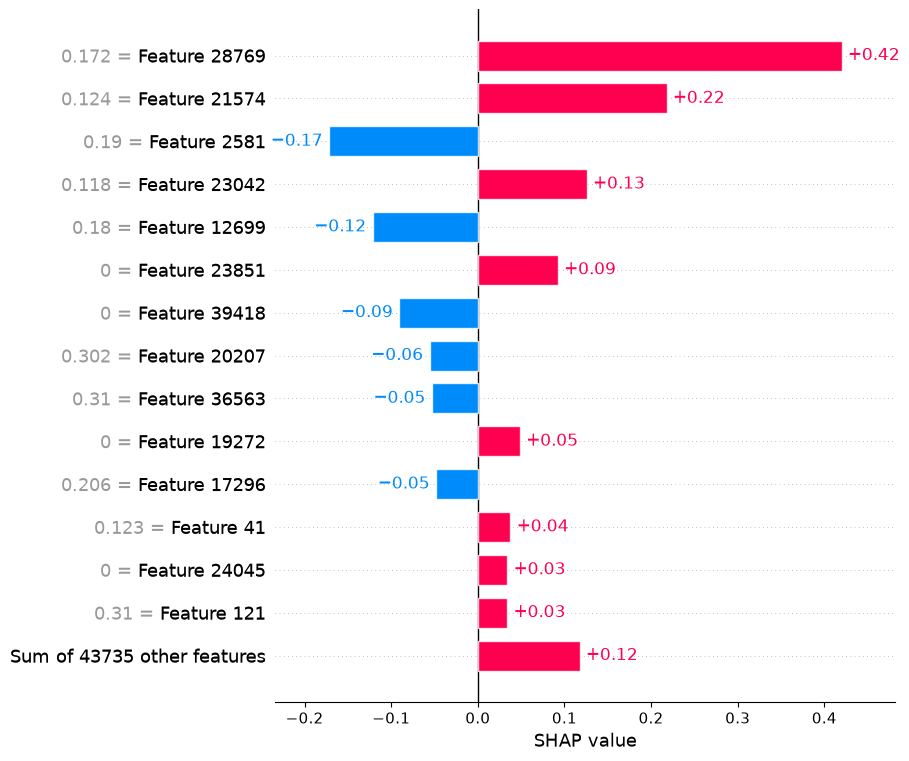

In [7]:
predicted_class = int(model.predict([sample_text])[0])

shap.plots.bar(
    shap_values[0, :, predicted_class],
    max_display=15
)

In [9]:
import shap

vectorizer = model.named_steps["tfidf"]
classifier = model.named_steps["classifier"]

# Select 50 training posts as the reference background
background_text = train_df["text"].sample(
    50, random_state=42
)
background = vectorizer.transform(background_text).toarray()

# Convert the validation post to TF-IDF features
X_sample = vectorizer.transform([sample_text]).toarray()

# Use a SHAP explainer suited to linear models
explainer = shap.LinearExplainer(classifier, background)
shap_values = explainer(X_sample)

print("SHAP values calculated!")
print("Explanation shape:", shap_values.values.shape)

SHAP values calculated!
Explanation shape: (1, 43749, 3)


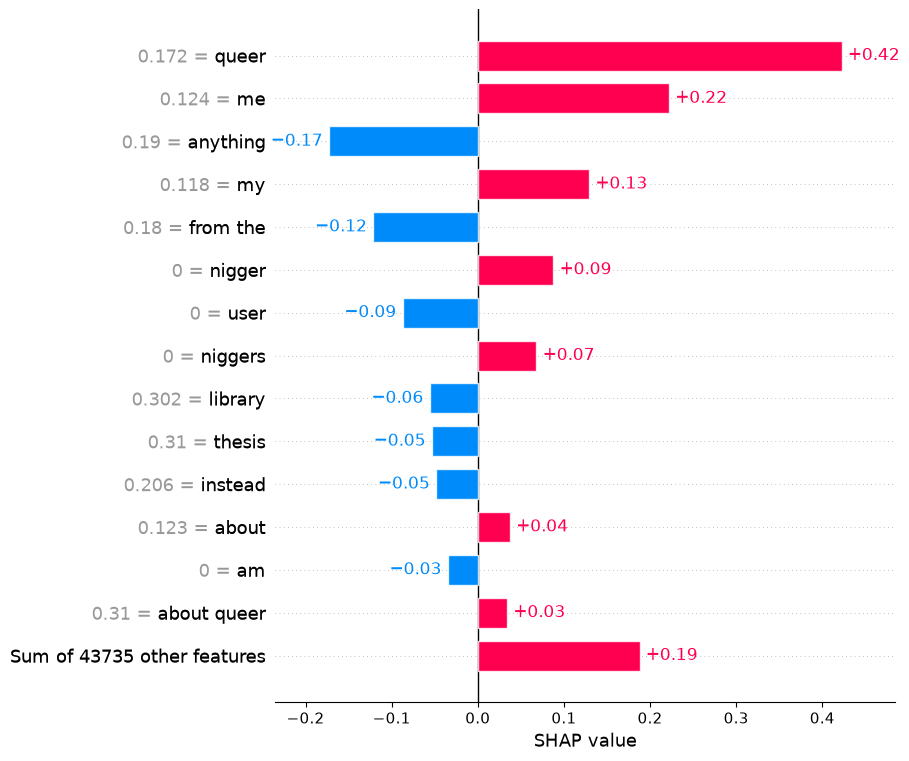

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import shap

feature_names = vectorizer.get_feature_names_out()
predicted_class = int(model.predict([sample_text])[0])

class_explanation = shap.Explanation(
    values=shap_values.values[0, :, predicted_class],
    base_values=shap_values.base_values[0, predicted_class],
    data=X_sample[0],
    feature_names=feature_names
)

shap.plots.bar(class_explanation, max_display=15)

In [11]:
from pathlib import Path
import matplotlib.pyplot as plt

results_dir = Path.home() / "Downloads" / "Hate-Speech-Detection" / "results" / "figures"
results_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(results_dir / "shap_baseline_explanation.png",
            dpi=300, bbox_inches="tight")
print("SHAP figure saved!")

SHAP figure saved!


<Figure size 640x480 with 0 Axes>

In [12]:
import ast
import numpy as np

sample = val_df.iloc[0]

tokens = ast.literal_eval(sample["text"]) if isinstance(sample["text"], str) and sample["text"].startswith("[") else sample["text"].split()
rationales = ast.literal_eval(sample["rationales"]) if isinstance(sample["rationales"], str) else sample["rationales"]

print("Post:", sample["text"])
print("Human rationales:", rationales)

Post: me getting books from the library about queer cowboys and homoeroticism in cinema instead of anything useful for my thesis
Human rationales: []


In [13]:
import ast

def parse_value(value):
    if isinstance(value, str):
        try:
            return ast.literal_eval(value)
        except (ValueError, SyntaxError):
            return value
    return value

for i, row in val_df.iterrows():
    rationales = parse_value(row["rationales"])

    if isinstance(rationales, list) and len(rationales) > 0:
        if any(isinstance(r, list) and sum(r) > 0 for r in rationales):
            print("Row:", i)
            print("Post:", row["text"])
            print("Human rationales:", rationales)
            break
else:
    print("No non-empty rationales found in validation CSV.")

Row: 18
Post: democrats from minnesota leftist muzzie shithole are the dumbest anti americans there are klobuchar one of the reps is a dumb bitch who has a moronic position on the tax bill fuck this stupid woman
Human rationales: [[0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0], [0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1]]


In [14]:
import ast

sample = val_df.iloc[18]

text = sample["text"]
rationales = ast.literal_eval(sample["rationales"]) if isinstance(sample["rationales"], str) else sample["rationales"]

tokens = text.split()

print("Number of tokens:", len(tokens))
print("Number of rationale annotations:", len(rationales))

for i, rationale in enumerate(rationales):
    print(f"\nAnnotator {i + 1}:")
    if len(rationale) == len(tokens):
        print("Important words:", [word for word, score in zip(tokens, rationale) if score == 1])
    else:
        print("Token counts don't match; we need to inspect the original tokenization.")

Number of tokens: 35
Number of rationale annotations: 3

Annotator 1:
Important words: ['muzzie', 'dumbest', 'anti', 'americans']

Annotator 2:
Important words: ['muzzie', 'shithole', 'fuck']

Annotator 3:
Important words: ['muzzie', 'shithole', 'dumb', 'bitch', 'stupid', 'woman']


In [16]:
sample_text = val_df.iloc[18]["text"]

prediction = model.predict([sample_text])[0]
probabilities = model.predict_proba([sample_text])[0]

print("Post:", sample_text)
print("Predicted class:", class_names[prediction])
print("\nClass probabilities:")

for i, probability in enumerate(probabilities):
    print(f"{class_names[i]}: {probability:.4f}")

Post: democrats from minnesota leftist muzzie shithole are the dumbest anti americans there are klobuchar one of the reps is a dumb bitch who has a moronic position on the tax bill fuck this stupid woman
Predicted class: Hate speech

Class probabilities:
Hate speech: 0.5413
Normal: 0.0722
Offensive: 0.3866


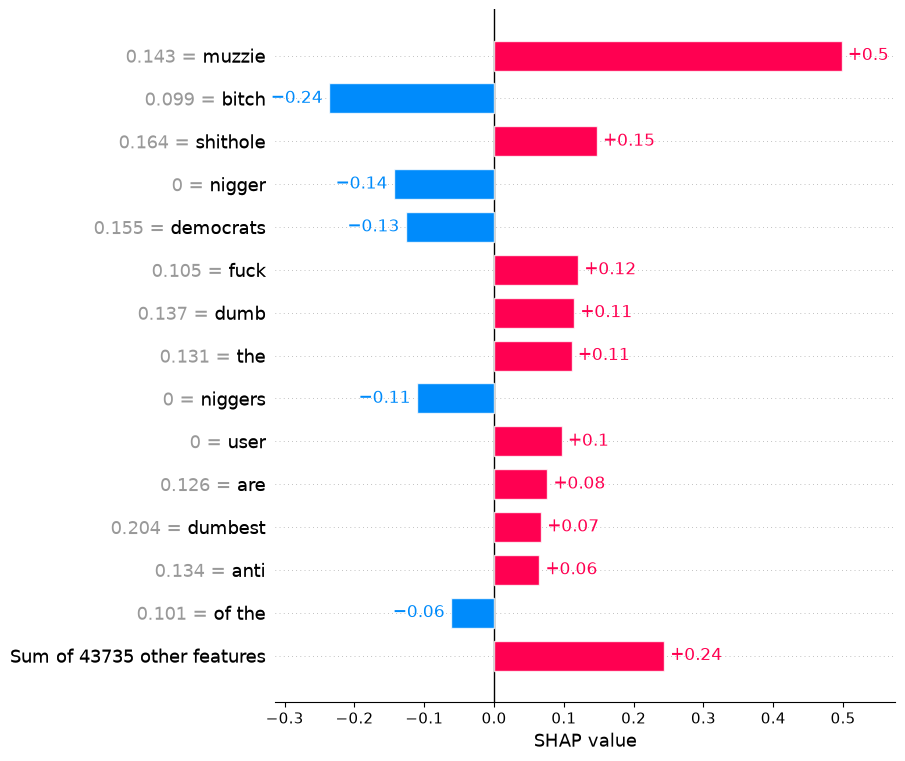

In [20]:
import numpy as np
import shap

vectorizer = model.named_steps["tfidf"]
classifier = model.named_steps["classifier"]

# Human-consensus example
sample_text = val_df.iloc[18]["text"]
X_sample = vectorizer.transform([sample_text]).toarray()

# Explain the predicted class
predicted_class = int(model.predict([sample_text])[0])

background_text = train_df["text"].sample(50, random_state=42)
background = vectorizer.transform(background_text).toarray()

explainer = shap.LinearExplainer(classifier, background)
shap_values = explainer(X_sample)

feature_names = vectorizer.get_feature_names_out()

explanation = shap.Explanation(
    values=shap_values.values[0, :, predicted_class],
    base_values=shap_values.base_values[0, predicted_class],
    data=X_sample[0],
    feature_names=feature_names
)

shap.plots.bar(explanation, max_display=15)

In [21]:
import numpy as np
import ast

# Get the original human rationale from the exploration notebook's saved CSV
original_sample = val_df.iloc[18]

rationales = original_sample["rationales"]
if isinstance(rationales, str):
    rationales = ast.literal_eval(rationales)

tokens = original_sample["text"].split()
rationales = np.array(rationales)

# Majority-vote human rationale
consensus = rationales.sum(axis=0) >= 2
human_words = {
    word for word, selected in zip(tokens, consensus) if selected
}

# Top 15 features by absolute SHAP value
shap_values_for_class = shap_values.values[0, :, predicted_class]
top_indices = np.argsort(np.abs(shap_values_for_class))[-15:]
top_shap_words = set(feature_names[top_indices])

overlap = human_words & top_shap_words

print("Human rationale words:", human_words)
print("Overlapping words:", overlap)
print(
    "Human rationale coverage:",
    round(len(overlap) / len(human_words), 3) if human_words else 0
)

Human rationale words: {'shithole', 'muzzie'}
Overlapping words: {'shithole', 'muzzie'}
Human rationale coverage: 1.0


In [23]:
import ast
import numpy as np
import pandas as pd

results = []

for i in range(min(50, len(val_df))):
    row = val_df.iloc[i]

    rationales = row["rationales"]
    if isinstance(rationales, str):
        rationales = ast.literal_eval(rationales)

    tokens = row["text"].split()
    rationales = np.array(rationales)

    # Skip examples where rationale masks don't align with text tokens
    if rationales.ndim != 2 or rationales.shape[1] != len(tokens):
        continue

    consensus = rationales.sum(axis=0) >= 2
    human_words = {
        word.lower()
        for word, selected in zip(tokens, consensus)
        if selected
    }

    if not human_words:
        continue

    text = row["text"]
    predicted_class = int(model.predict([text])[0])

    X_sample = vectorizer.transform([text]).toarray()
    explanation_values = explainer(X_sample)

    values = explanation_values.values[0, :, predicted_class]
    top_indices = np.argsort(np.abs(values))[-15:]
    top_shap_words = {
        feature_names[j].lower()
        for j in top_indices
    }

    overlap = human_words & top_shap_words

    results.append({
        "row": i,
        "human_rationale_count": len(human_words),
        "overlap_count": len(overlap),
        "coverage": len(overlap) / len(human_words)
    })

results_df = pd.DataFrame(results)

print("Posts evaluated:", len(results_df))

if not results_df.empty:
    print(
        "Mean human-rationale coverage:",
        round(results_df["coverage"].mean(), 3)
    )
    display(results_df.head())
else:
    print("No valid examples found. We need to inspect token alignment.")

Posts evaluated: 19
Mean human-rationale coverage: 0.893


,row,human_rationale_count,overlap_count,coverage
0,18,2,2,1.000000
1,20,5,3,0.600000
2,21,2,2,1.000000
3,25,2,2,1.000000
4,26,11,5,0.454545


In [24]:
from pathlib import Path

results_dir = Path.home() / "Downloads" / "Hate-Speech-Detection" / "results" / "tables"
results_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    results_dir / "preliminary_shap_rationale_coverage.csv",
    index=False
)

print("Results saved successfully!")
print("File:", results_dir / "preliminary_shap_rationale_coverage.csv")

Results saved successfully!
File: /Users/aadya/Downloads/Hate-Speech-Detection/results/tables/preliminary_shap_rationale_coverage.csv


In [27]:
print("Validation columns:")
print(val_df.columns.tolist())

print("\nSample row:")
print(val_df.iloc[18].to_dict().keys())

Validation columns:
['id', 'text', 'label', 'rationales', 'annotator_labels', 'label_name']

Sample row:
dict_keys(['id', 'text', 'label', 'rationales', 'annotator_labels', 'label_name'])


In [37]:

import ast
import numpy as np

def parse_value(value):
    if isinstance(value, str):
        try:
            return ast.literal_eval(value)
        except (ValueError, SyntaxError):
            return value
    return value


def evaluate_rationale(row_index):
    row = val_df.iloc[row_index]
    text = row["text"]
    rationales = parse_value(row["rationales"])

    if not isinstance(rationales, (list, tuple, np.ndarray)) or len(rationales) == 0:
        print("No human rationales available for this post.")
        return None

    print("Post:", text)
    print("Label:", row["label_name"])
    print("Rationale annotations:", len(rationales))

    tokens = text.split()

    valid_masks = [
        mask for mask in rationales
        if isinstance(mask, (list, tuple, np.ndarray))
        and len(mask) == len(tokens)
    ]

    if not valid_masks:
        print("Rationale masks do not align with whitespace tokens.")
        return None

    consensus = (
        np.asarray(valid_masks, dtype=int).sum(axis=0)
        >= (len(valid_masks) / 2)
    )

    human_words = {
        token.lower()
        for token, selected in zip(tokens, consensus)
        if selected
    }

    print("Human consensus words:", human_words)

    if not human_words:
        print("No consensus rationale words found.")
        return None

    predicted_class = int(model.predict([text])[0])
    X_sample = vectorizer.transform([text]).toarray()
    explanation = explainer(X_sample)
    values = explanation.values[0, :, predicted_class]

    feature_names = vectorizer.get_feature_names_out()
    top_indices = np.argsort(np.abs(values))[-15:]

    top_words = {
        feature_names[i].lower()
        for i in top_indices
    }

    overlap = human_words & top_words
    coverage = len(overlap) / len(human_words)

    print("Top SHAP words:", top_words)
    print("Overlapping words:", overlap)
    print("Human rationale coverage:", round(coverage, 3))

    return {
        "row": row_index,
        "label": row["label_name"],
        "human_word_count": len(human_words),
        "overlap_count": len(overlap),
        "coverage": coverage,
        "overlapping_words": sorted(overlap)
    }


evaluate_rationale(18)


Post: democrats from minnesota leftist muzzie shithole are the dumbest anti americans there are klobuchar one of the reps is a dumb bitch who has a moronic position on the tax bill fuck this stupid woman
Label: Hate speech
Rationale annotations: 3
Human consensus words: {'shithole', 'muzzie'}
Top SHAP words: {'anti', 'nigger', 'bitch', 'muzzie', 'shithole', 'the', 'niggers', 'dumb', 'are', 'fuck', 'of the', 'user', 'democrats', 'stupid', 'dumbest'}
Overlapping words: {'shithole', 'muzzie'}
Human rationale coverage: 1.0


{'row': 18,
 'label': 'Hate speech',
 'human_word_count': 2,
 'overlap_count': 2,
 'coverage': 1.0,
 'overlapping_words': ['muzzie', 'shithole']}

In [38]:
results = []

for i in range(min(100, len(val_df))):
    try:
        result = evaluate_rationale(i)
        if isinstance(result, dict):
            results.append(result)
    except Exception as e:
        print(f"Skipped row {i}: {e}")

results_df = pd.DataFrame(results)

print("Posts evaluated:", len(results_df))

if not results_df.empty:
    print("Mean human-rationale coverage:", round(results_df["coverage"].mean(), 3))
    display(results_df.head())
else:
    print("No valid results. Check the evaluate_rationale function.")

No human rationales available for this post.
No human rationales available for this post.
No human rationales available for this post.
No human rationales available for this post.
No human rationales available for this post.
No human rationales available for this post.
No human rationales available for this post.
No human rationales available for this post.
No human rationales available for this post.
No human rationales available for this post.
No human rationales available for this post.
No human rationales available for this post.
No human rationales available for this post.
No human rationales available for this post.
No human rationales available for this post.
No human rationales available for this post.
No human rationales available for this post.
No human rationales available for this post.
Post: democrats from minnesota leftist muzzie shithole are the dumbest anti americans there are klobuchar one of the reps is a dumb bitch who has a moronic position on the tax bill fuck this

,row,label,human_word_count,overlap_count,coverage,overlapping_words
0,18,Hate speech,2,2,1.00,"[muzzie, shithole]"
1,20,Offensive,8,6,0.75,"[hard, lesbian, nsfw, she, single, soft]"
2,21,Hate speech,5,3,0.60,"[cuck, fuck, gay]"
3,25,Offensive,6,6,1.00,"[corrupt, elites, genocide, jews, politicians,..."
4,26,Hate speech,25,9,0.36,"[aids, by, dies, fucked, hope, needs, niggers,..."


In [39]:
test_result = evaluate_rationale(18)

print("Return type:", type(test_result))
print("Return value:", test_result)

Post: democrats from minnesota leftist muzzie shithole are the dumbest anti americans there are klobuchar one of the reps is a dumb bitch who has a moronic position on the tax bill fuck this stupid woman
Label: Hate speech
Rationale annotations: 3
Human consensus words: {'shithole', 'muzzie'}
Top SHAP words: {'anti', 'nigger', 'bitch', 'muzzie', 'shithole', 'the', 'niggers', 'dumb', 'are', 'fuck', 'of the', 'user', 'democrats', 'stupid', 'dumbest'}
Overlapping words: {'shithole', 'muzzie'}
Human rationale coverage: 1.0
Return type: <class 'dict'>
Return value: {'row': 18, 'label': 'Hate speech', 'human_word_count': 2, 'overlap_count': 2, 'coverage': 1.0, 'overlapping_words': ['muzzie', 'shithole']}


In [42]:
print("Posts evaluated:", len(results_df))

print("\nCoverage statistics:")
display(results_df["coverage"].describe())

print("\nLowest-coverage examples:")
display(
    results_df.sort_values("coverage")[
        ["row", "human_word_count", "overlap_count", "coverage"]
    ].head(10)
)

Posts evaluated: 53

Coverage statistics:


count    53.000000
mean      0.757975
std       0.297528
min       0.000000
25%       0.500000
50%       1.000000
75%       1.000000
max       1.000000
Name: coverage, dtype: float64


Lowest-coverage examples:


,row,human_word_count,overlap_count,coverage
20,51,1,0,0.000000
46,88,5,1,0.200000
34,69,42,9,0.214286
21,52,9,2,0.222222
51,98,16,5,0.312500
35,71,24,8,0.333333
24,58,3,1,0.333333
22,54,20,7,0.350000
4,26,25,9,0.360000
52,99,19,7,0.368421


In [43]:
from pathlib import Path

results_dir = Path.home() / "Downloads" / "Hate-Speech-Detection" / "results" / "tables"
results_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    results_dir / "shap_rationale_alignment.csv",
    index=False
)

print("Rationale-alignment results saved successfully!")

Rationale-alignment results saved successfully!


In [44]:

import numpy as np
import pandas as pd

# Select one validation post
text = val_df.iloc[18]["text"]
original_class = int(model.predict([text])[0])
original_probs = model.predict_proba([text])[0]
original_confidence = original_probs[original_class]

# Calculate SHAP values for this post
X_sample = vectorizer.transform([text]).toarray()
explanation = explainer(X_sample)
shap_values = explanation.values[0, :, original_class]

feature_names = vectorizer.get_feature_names_out()
tokens = text.split()

# Select influential unigram features that actually occur in the post
token_scores = {}
for i, feature in enumerate(feature_names):
    if " " not in feature and feature in tokens:
        token_scores[feature] = abs(shap_values[i])

top_words = sorted(
    token_scores,
    key=token_scores.get,
    reverse=True
)[:5]

# Remove the selected words
removed_text = " ".join(
    token for token in tokens if token not in top_words
)

# Keep only the selected words
kept_text = " ".join(
    token for token in tokens if token in top_words
)

removed_confidence = model.predict_proba([removed_text])[0][original_class]
kept_confidence = model.predict_proba([kept_text])[0][original_class]

comprehensiveness = original_confidence - removed_confidence
sufficiency_gap = abs(original_confidence - kept_confidence)

print("Original prediction:", original_class)
print("Top SHAP words:", top_words)
print("Original confidence:", round(original_confidence, 4))
print("Confidence after removing words:", round(removed_confidence, 4))
print("Confidence using only selected words:", round(kept_confidence, 4))
print("Comprehensiveness:", round(comprehensiveness, 4))
print("Sufficiency gap:", round(sufficiency_gap, 4))


Original prediction: 0
Top SHAP words: ['muzzie', 'bitch', 'shithole', 'democrats', 'fuck']
Original confidence: 0.5413
Confidence after removing words: 0.4789
Confidence using only selected words: 0.3919
Comprehensiveness: 0.0623
Sufficiency gap: 0.1494


In [45]:

from pathlib import Path
import pandas as pd

faithfulness_results = pd.DataFrame([{
    "row": 18,
    "predicted_class": original_class,
    "original_confidence": original_confidence,
    "confidence_after_removal": removed_confidence,
    "confidence_using_only_selected_words": kept_confidence,
    "comprehensiveness": comprehensiveness,
    "sufficiency_gap": sufficiency_gap,
    "selected_words": ", ".join(top_words)
}])

results_dir = (
    Path.home() / "Downloads" / "Hate-Speech-Detection"
    / "results" / "tables"
)
results_dir.mkdir(parents=True, exist_ok=True)

faithfulness_results.to_csv(
    results_dir / "shap_faithfulness.csv",
    index=False
)

print("Faithfulness results saved successfully!")

Faithfulness results saved successfully!


In [46]:

import re
import numpy as np
import pandas as pd
from pathlib import Path

vectorizer = model.named_steps["tfidf"]
feature_names = vectorizer.get_feature_names_out()

faithfulness_rows = []
sample_df = val_df.sample(
    n=min(30, len(val_df)),
    random_state=42
)

for row_index, row in sample_df.iterrows():
    text = str(row["text"])

    # Original prediction and confidence
    original_class = int(model.predict([text])[0])
    original_probs = model.predict_proba([text])[0]
    original_confidence = float(original_probs[original_class])

    # Calculate SHAP values for the predicted class
    X_sample = vectorizer.transform([text]).toarray()
    explanation = explainer(X_sample)
    shap_values = explanation.values[0, :, original_class]

    # Rank unigram features that actually occur in the post
    present_indices = vectorizer.transform([text]).indices
    candidates = [
        i for i in present_indices
        if " " not in feature_names[i]
    ]

    top_indices = sorted(
        candidates,
        key=lambda i: abs(shap_values[i]),
        reverse=True
    )[:5]

    top_words = [feature_names[i] for i in top_indices]

    # Remove the selected words from the original post
    removed_text = text
    for word in top_words:
        removed_text = re.sub(
            r"\b" + re.escape(word) + r"\b",
            " ",
            removed_text,
            flags=re.IGNORECASE
        )

    # Keep only the selected words
    kept_tokens = re.findall(r"\b\w+\b", text.lower())
    kept_text = " ".join(
        token for token in kept_tokens
        if token in set(top_words)
    )

    removed_confidence = float(
        model.predict_proba([removed_text])[0][original_class]
    )

    kept_confidence = float(
        model.predict_proba([kept_text])[0][original_class]
    )

    faithfulness_rows.append({
        "row": row_index,
        "predicted_class": original_class,
        "original_confidence": original_confidence,
        "confidence_after_removal": removed_confidence,
        "confidence_using_only_selected_words": kept_confidence,
        "comprehensiveness": (
            original_confidence - removed_confidence
        ),
        "sufficiency_gap": abs(
            original_confidence - kept_confidence
        ),
        "selected_words": ", ".join(top_words)
    })

faithfulness_df = pd.DataFrame(faithfulness_rows)

print("Posts evaluated:", len(faithfulness_df))
print(
    "Mean comprehensiveness:",
    round(faithfulness_df["comprehensiveness"].mean(), 4)
)
print(
    "Mean sufficiency gap:",
    round(faithfulness_df["sufficiency_gap"].mean(), 4)
)

display(faithfulness_df.head(10))

results_dir = (
    Path.home() / "Downloads" / "Hate-Speech-Detection"
    / "results" / "tables"
)
results_dir.mkdir(parents=True, exist_ok=True)

faithfulness_df.to_csv(
    results_dir / "shap_faithfulness_multi_example.csv",
    index=False
)

print("Results saved successfully!")


Posts evaluated: 30
Mean comprehensiveness: 0.2196
Mean sufficiency gap: 0.1275


,row,predicted_class,original_confidence,confidence_after_removal,confidence_using_only_selected_words,comprehensiveness,sufficiency_gap,selected_words
0,1259,1,0.444108,0.478932,0.444108,-0.034824,0.000000,"faggots, lot, my, parking, in"
1,1623,0,0.868171,0.180828,0.990219,0.687343,0.122048,"nigger, make, why, which, them"
2,611,0,0.727983,0.302757,0.974666,0.425225,0.246683,"moslem, whore, monkey, will, should"
3,514,1,0.497426,0.333735,0.407711,0.163691,0.089715,"muslims, all, around, my, world"
4,413,1,0.418159,0.360737,0.552614,0.057422,0.134455,"hair, touch, rape, what, wanting"
5,1075,0,0.405391,0.397807,0.196141,0.007584,0.209250,"women, it, hell, worst, corrupt"
6,538,1,0.688819,0.525616,0.691369,0.163203,0.002550,"user, are, everything, bad, asians"
7,482,1,0.617813,0.559219,0.657105,0.058593,0.039292,"islam, am, user, posting, officially"
8,398,2,0.411019,0.300722,0.598123,0.110297,0.187104,"retarded, of, all, face, nose"
9,677,0,0.468799,0.260359,0.422673,0.208440,0.046126,"whore, are, white, women, next"


Results saved successfully!


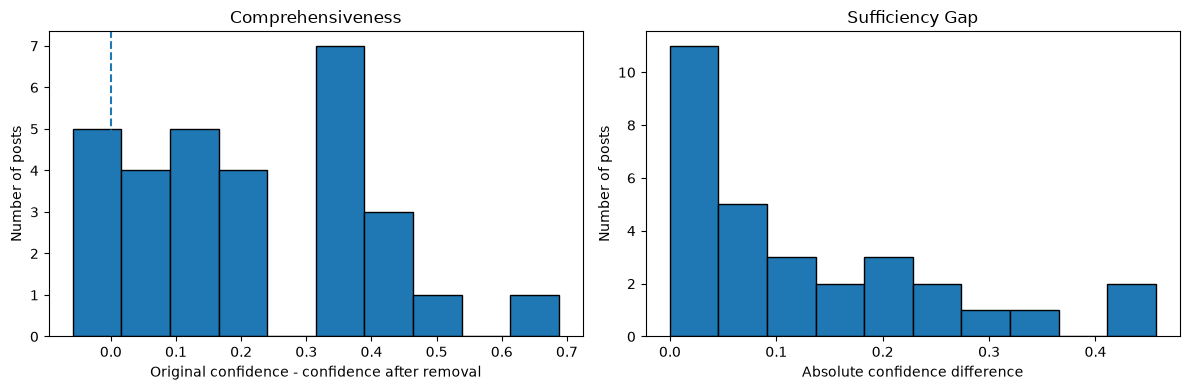

In [47]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    faithfulness_df["comprehensiveness"],
    bins=10,
    edgecolor="black"
)
axes[0].axvline(0, linestyle="--")
axes[0].set_title("Comprehensiveness")
axes[0].set_xlabel("Original confidence - confidence after removal")
axes[0].set_ylabel("Number of posts")

axes[1].hist(
    faithfulness_df["sufficiency_gap"],
    bins=10,
    edgecolor="black"
)
axes[1].set_title("Sufficiency Gap")
axes[1].set_xlabel("Absolute confidence difference")
axes[1].set_ylabel("Number of posts")

plt.tight_layout()
plt.show()

In [48]:
from pathlib import Path
import matplotlib.pyplot as plt

results_dir = (
    Path.home()
    / "Downloads"
    / "Hate-Speech-Detection"
    / "results"
    / "figures"
)

results_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    results_dir / "shap_faithfulness_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

print("Graphs saved successfully!")

Graphs saved successfully!


<Figure size 640x480 with 0 Axes>